# German Bundestag: complete MP list

Extract one record for every person in the official `MdB-Stammdaten.xml` file, including former members from earlier election periods. The source archive and generated CSV are in `../datasets/`.

In [8]:
import re
import unicodedata

HEUTE = pd.Timestamp.today().normalize()
DATUMSFORMAT = "%d.%m.%Y"
de = lambda n: f"{n:,}".replace(",", ".")            # Tausenderpunkt

def flatten_fields(element, prefix="", skip=()):
    """Gibt die direkten Textfelder eines XML-Elements als Dictionary zurück."""
    if element is None:
        return {}
    return {prefix + c.tag: (c.text or "").strip() or None
            for c in element if c.tag not in skip}

def to_date(series):
    return pd.to_datetime(series, format=DATUMSFORMAT, errors="coerce")

def norm(s):
    """Kleingeschriebener ASCII-Schlüssel für Namensabgleiche (ä -> ae usw.)."""
    s = (s or "").lower()
    for a, b in (("ä", "ae"), ("ö", "oe"), ("ü", "ue"), ("ß", "ss")):
        s = s.replace(a, b)
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z]+", " ", s).strip()

# ---------------------------------------------------------------- 1) XML einlesen
members, name_rows, term_rows, inst_rows = [], [], [], []

for member in root.findall("MDB"):
    mid = member.findtext("ID")
    names = member.findall("NAMEN/NAME")
    latest = next((n for n in names if not (n.findtext("HISTORIE_BIS") or "").strip()),
                  names[-1] if names else None)

    row = {"ID": mid}
    row.update(flatten_fields(latest, "NAME_"))
    row.update(flatten_fields(member.find("BIOGRAFISCHE_ANGABEN")))
    row["NAMEN_ALLE"] = " | ".join(
        f"{n.findtext('VORNAME') or ''} {n.findtext('NACHNAME') or ''}".strip() for n in names)
    row["ANZAHL_NAMEN"] = len(names)
    members.append(row)

    for n in names:                                   # jeder Name, den das Mitglied je hatte
        name_rows.append({"ID": mid, **flatten_fields(n)})

    for wp in member.findall("WAHLPERIODEN/WAHLPERIODE"):
        term_rows.append({"ID": mid, **flatten_fields(wp, skip=("INSTITUTIONEN",))})
        for ins in wp.findall("INSTITUTIONEN/INSTITUTION"):
            inst_rows.append({"ID": mid, "WP": wp.findtext("WP"), **flatten_fields(ins)})

all_mps = pd.DataFrame(members)
names_df = pd.DataFrame(name_rows)
terms = pd.DataFrame(term_rows)
inst = pd.DataFrame(inst_rows)

# ---------------------------------------------------------------- 2) Typen und Datumsfelder
terms["WP"] = pd.to_numeric(terms["WP"])
inst["WP"] = pd.to_numeric(inst["WP"])
for c in ("MDBWP_VON", "MDBWP_BIS"):
    terms[c] = to_date(terms[c])
for c in ("MDBINS_VON", "MDBINS_BIS", "FKTINS_VON", "FKTINS_BIS"):
    if c in inst:
        inst[c] = to_date(inst[c])
for c in ("HISTORIE_VON", "HISTORIE_BIS"):
    if c in names_df:
        names_df[c] = to_date(names_df[c])

names_df["NAME_SCHLUESSEL"] = (names_df["NACHNAME"].fillna("") + " " + names_df["VORNAME"].fillna("")).map(norm)

# ---------------------------------------------------------------- 3) Jahre pro Wahlperiode
letzte_wp = terms["WP"].max()
ende = terms["MDBWP_BIS"].copy()
ende[terms["MDBWP_BIS"].isna() & (terms["WP"] == letzte_wp)] = HEUTE   # nur die aktuelle WP läuft bis heute
terms["JAHRE"] = ((ende - terms["MDBWP_VON"]).dt.days / 365.25).round(2)

# ---------------------------------------------------------------- 4) Zusammenfassung pro Mitglied
g = terms.groupby("ID")
summary = pd.DataFrame({
    "WAHLPERIODEN": g["WP"].apply(lambda s: ", ".join(str(x) for x in sorted(s))),
    "ANZAHL_WAHLPERIODEN": g.size(),
    "ERSTE_WP": g["WP"].min(),
    "LETZTE_WP": g["WP"].max(),
    "ERSTER_EINTRITT": g["MDBWP_VON"].min(),
    "JAHRE_GESAMT": g["JAHRE"].sum(min_count=1).round(1),
})
akt = terms[terms["WP"] == letzte_wp]
summary["IN_AKTUELLER_WP"] = summary.index.isin(akt["ID"])
summary["AKTUELL_MDB"] = summary.index.isin(akt.loc[akt["MDBWP_BIS"].isna(), "ID"])
all_mps = all_mps.merge(summary, left_on="ID", right_index=True, how="left")

# ---------------------------------------------------------------- 5) Datum, Alter, Parteigruppe
geburt = to_date(all_mps["GEBURTSDATUM"])
tod = to_date(all_mps["STERBEDATUM"])
nicht_lesbar_geburt = int((geburt.isna() & all_mps["GEBURTSDATUM"].notna()).sum())   # vor dem Überschreiben prüfen
nicht_lesbar_tod = int((tod.isna() & all_mps["STERBEDATUM"].notna()).sum())

ref = tod.fillna(HEUTE)                                  # Alter bei Tod, sonst Alter heute
hatte_geburtstag = (ref.dt.month > geburt.dt.month) | (
    (ref.dt.month == geburt.dt.month) & (ref.dt.day >= geburt.dt.day))
all_mps["GEBURTSDATUM"], all_mps["STERBEDATUM"] = geburt, tod
all_mps["GEBURTSJAHR"] = geburt.dt.year.astype("Int64")
all_mps["LEBT"] = tod.isna()                             # True = kein Sterbedatum erfasst
all_mps["ALTER"] = (ref.dt.year - geburt.dt.year - (~hatte_geburtstag).astype(int)).astype("Int64")

# Vereinheitlichte Parteispalte; PARTEI_KURZ bleibt unverändert
PARTEI_MAP = {
    "BÜNDNIS 90/DIE GRÜNEN": "BÜNDNIS 90/DIE GRÜNEN",
    "GRÜNE": "BÜNDNIS 90/DIE GRÜNEN",
    "DIE GRÜNEN/BÜNDNIS 90": "BÜNDNIS 90/DIE GRÜNEN",
    "DIE LINKE.": "DIE LINKE/PDS",
    "PDS": "DIE LINKE/PDS",
    "PDS/LL": "DIE LINKE/PDS",
    "Plos": "parteilos",
}
all_mps["PARTEI_GRUPPE"] = all_mps["PARTEI_KURZ"].map(PARTEI_MAP).fillna(all_mps["PARTEI_KURZ"])

# ---------------------------------------------------------------- 6) Fraktion je Zeitraum (für "Fraktion zum Zeitpunkt der Abstimmung")
FRAKTION_REGELN = [("Sozialdemokrat", "SPD"), ("Christlich", "CDU/CSU"), ("Freien Demokrat", "FDP"),
                   ("Alternative", "AfD"), ("GRÜNEN|BÜNDNIS 90", "GRÜNE"),
                   ("LINKE|PDS", "LINKE/PDS"), ("Sahra", "BSW")]

def fraktion_kurz(langname):
    for muster, kurz in FRAKTION_REGELN:
        if isinstance(langname, str) and re.search(muster, langname, flags=re.I):
            return kurz
    return langname

fak = (inst[inst["INSART_LANG"] == "Fraktion/Gruppe"]
       .merge(terms[["ID", "WP", "MDBWP_VON", "MDBWP_BIS"]], on=["ID", "WP"], how="left"))
fak["VON"] = fak["MDBINS_VON"].fillna(fak["MDBWP_VON"])      # ohne eigene Daten -> ganze Wahlperiode
fak["BIS"] = fak["MDBINS_BIS"].fillna(fak["MDBWP_BIS"])      # leer = noch offen
factions = fak[["ID", "WP", "INS_LANG", "VON", "BIS"]].rename(columns={"INS_LANG": "FRAKTION"})
factions["FRAKTION_KURZ"] = factions["FRAKTION"].map(fraktion_kurz)
# Mitglieder ohne Zeile hier saßen in der jeweiligen Wahlperiode als fraktionslos.

# ---------------------------------------------------------------- 7) Prüfungen und Speichern
assert all_mps["ID"].notna().all() and all_mps["ID"].is_unique, "IDs müssen eindeutig sein"
assert set(terms["ID"]) <= set(all_mps["ID"]), "Wahlperioden enthalten unbekannte IDs"
print("Nicht lesbare Geburtsdaten:", nicht_lesbar_geburt, "| nicht lesbare Sterbedaten:", nicht_lesbar_tod)
print("Ohne erfasstes Sterbedatum, aber älter als 100 (vermutlich nicht erfasste Todesfälle):",
      int(((all_mps["ALTER"] > 100) & all_mps["LEBT"]).sum()))

all_mps = all_mps.dropna(axis=1, how="all")
fmt = dict(index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
all_mps.to_csv(OUTPUT_CSV, **fmt)
names_df.to_csv(DATA_DIR / "Bundestag_MPs_namen.csv", **fmt)
terms.to_csv(DATA_DIR / "Bundestag_MPs_wahlperioden.csv", **fmt)
inst.to_csv(DATA_DIR / "Bundestag_MPs_institutionen.csv", **fmt)
factions.to_csv(DATA_DIR / "Bundestag_MPs_fraktionen.csv", **fmt)

print(f"{de(len(all_mps))} Mitglieder | {de(len(names_df))} Namen | {de(len(terms))} Mitglieds-Wahlperioden | "
      f"{de(len(inst))} Institutionszeilen | {de(len(factions))} Fraktionsphasen")
all_mps.head()

Nicht lesbare Geburtsdaten: 0 | nicht lesbare Sterbedaten: 0
Ohne erfasstes Sterbedatum, aber älter als 100 (vermutlich nicht erfasste Todesfälle): 0
4.614 Mitglieder | 4.901 Namen | 13.046 Mitglieds-Wahlperioden | 16.955 Institutionszeilen | 13.579 Fraktionsphasen


,ID,NAME_NACHNAME,NAME_VORNAME,NAME_ORTSZUSATZ,NAME_ADEL,NAME_PRAEFIX,NAME_ANREDE_TITEL,NAME_AKAD_TITEL,NAME_HISTORIE_VON,GEBURTSDATUM,...,ERSTE_WP,LETZTE_WP,ERSTER_EINTRITT,JAHRE_GESAMT,IN_AKTUELLER_WP,AKTUELL_MDB,GEBURTSJAHR,LEBT,ALTER,PARTEI_GRUPPE
0,11000001,Abelein,Manfred,None,None,None,Dr.,Prof. Dr.,19.10.1965,1930-10-20,...,5,11,1965-10-19,24.9,False,False,1930,False,77,CDU
1,11000002,Achenbach,Ernst,None,None,None,Dr.,Dr.,15.10.1957,1909-04-09,...,3,7,1957-10-15,18.9,False,False,1909,False,82,FDP
2,11000003,Ackermann,Annemarie,None,None,None,None,None,06.10.1953,1913-05-26,...,2,4,1953-10-06,8.8,False,False,1913,False,80,CDU
3,11000004,Ackermann,Else,None,None,None,Dr.,Dr.,03.10.1990,1933-11-06,...,11,12,1990-10-03,3.3,False,False,1933,False,85,CDU
4,11000005,Adam,Ulrich,None,None,None,None,None,20.12.1990,1950-06-09,...,12,16,1990-12-20,18.8,False,False,1950,True,76,CDU


## Metadatenchecks

Die folgenden Checks untersuchen die f?nf exportierten Tabellen: Mitglieder, Namen, Wahlperioden, Institutionen und Fraktionen.

In [9]:
tables = {
    "Mitglieder": all_mps,
    "Namen": names_df,
    "Wahlperioden": terms,
    "Institutionen": inst,
    "Fraktionen": factions,
}

overview = pd.DataFrame([
    {
        "Tabelle": name,
        "Zeilen": len(frame),
        "Spalten": len(frame.columns),
        "Spaltennamen": ", ".join(frame.columns),
    }
    for name, frame in tables.items()
])
display(overview)


,Tabelle,Zeilen,Spalten,Spaltennamen
0,Mitglieder,4614,33,"ID, NAME_NACHNAME, NAME_VORNAME, NAME_ORTSZUSA..."
1,Namen,4901,11,"ID, NACHNAME, VORNAME, ORTSZUSATZ, ADEL, PRAEF..."
2,Wahlperioden,13046,10,"ID, WP, MDBWP_VON, MDBWP_BIS, WKR_NUMMER, WKR_..."
3,Institutionen,16955,9,"ID, WP, INSART_LANG, INS_LANG, MDBINS_VON, MDB..."
4,Fraktionen,13579,6,"ID, WP, FRAKTION, VON, BIS, FRAKTION_KURZ"


In [10]:
missing_rows = []
for table_name, frame in tables.items():
    missing_counts = frame.isna().sum()
    for column, count in missing_counts[missing_counts > 0].items():
        missing_rows.append({
            "Tabelle": table_name,
            "Spalte": column,
            "Fehlend": int(count),
            "Prozent": round(count / len(frame) * 100, 2),
        })

missing_summary = pd.DataFrame(missing_rows)
if missing_summary.empty:
    print("Keine fehlenden Werte in den f?nf Tabellen.")
else:
    display(missing_summary.sort_values(["Tabelle", "Fehlend"], ascending=[True, False]))


,Tabelle,Spalte,Fehlend,Prozent
33,Fraktionen,BIS,634,4.67
32,Institutionen,FKTINS_BIS,16636,98.12
29,Institutionen,MDBINS_BIS,14392,84.88
31,Institutionen,FKTINS_VON,12840,75.73
30,Institutionen,FKT_LANG,12681,74.79
28,Institutionen,MDBINS_VON,4185,24.68
1,Mitglieder,NAME_ADEL,4575,99.15
2,Mitglieder,NAME_PRAEFIX,4529,98.16
0,Mitglieder,NAME_ORTSZUSATZ,4082,88.47
13,Mitglieder,VITA_KURZ,4007,86.84


In [11]:
member_ids = set(all_mps["ID"].dropna())
term_pairs = terms[["ID", "WP"]].drop_duplicates()
integrity_rows = []

for table_name, frame in tables.items():
    integrity_rows.append({
        "Tabelle": table_name,
        "Zeilen": len(frame),
        "fehlende IDs": int(frame["ID"].isna().sum()),
        "unbekannte Mitglieder": int((~frame["ID"].isin(member_ids)).sum()),
        "identische Duplikatzeilen": int(frame.duplicated().sum()),
    })

integrity_by_name = {row["Tabelle"]: row for row in integrity_rows}
for table_name, frame in [("Namen", names_df), ("Wahlperioden", terms),
                          ("Institutionen", inst), ("Fraktionen", factions)]:
    if {"ID", "WP"}.issubset(frame.columns):
        pairs = frame[["ID", "WP"]].drop_duplicates()
        unmatched = pairs.merge(term_pairs, on=["ID", "WP"], how="left", indicator=True)
        integrity_by_name[table_name]["Mitglied-WP ohne Wahlperiode"] = int(
            (unmatched["_merge"] == "left_only").sum()
        )

integrity = pd.DataFrame(integrity_rows).fillna(0)
display(integrity)
print("Doppelte ID-Wahlperioden-Schl?ssel:", int(terms.duplicated(["ID", "WP"]).sum()))


,Tabelle,Zeilen,fehlende IDs,unbekannte Mitglieder,identische Duplikatzeilen,Mitglied-WP ohne Wahlperiode
0,Mitglieder,4614,0,0,0,0.0
1,Namen,4901,0,0,0,0.0
2,Wahlperioden,13046,0,0,0,0.0
3,Institutionen,16955,0,0,0,0.0
4,Fraktionen,13579,0,0,66,0.0


Doppelte ID-Wahlperioden-Schl?ssel: 0


In [12]:
for column in ["GESCHLECHT", "PARTEI_KURZ", "PARTEI_GRUPPE", "IN_AKTUELLER_WP", "AKTUELL_MDB"]:
    if column in all_mps:
        print(f"\nMitglieder nach {column}")
        display(all_mps[column].value_counts(dropna=False).rename_axis(column).to_frame("Anzahl"))

period_counts = (
    terms.groupby("WP")
    .agg(Mitglieder=("ID", "nunique"), Mitgliedsperioden=("ID", "size"))
    .sort_index()
)
print("\nMitglieder und Mitgliedsperioden je Wahlperiode")
display(period_counts)

print("\nFraktionsphasen nach Kurzbezeichnung")
display(factions["FRAKTION_KURZ"].value_counts(dropna=False).rename_axis("Fraktion").to_frame("Phasen"))

print("\nInstitutionen nach Art")
display(inst["INSART_LANG"].value_counts(dropna=False).rename_axis("Institutionsart").to_frame("Zeilen"))



Mitglieder nach GESCHLECHT


,Anzahl
GESCHLECHT,
männlich,3567
weiblich,1046
divers,1



Mitglieder nach PARTEI_KURZ


,Anzahl
PARTEI_KURZ,
SPD,1451
CDU,1441
FDP,491
CSU,285
BÜNDNIS 90/DIE GRÜNEN,266
AfD,199
DIE LINKE.,174
PDS,54
GRÜNE,50



Mitglieder nach PARTEI_GRUPPE


,Anzahl
PARTEI_GRUPPE,
SPD,1451
CDU,1441
FDP,491
BÜNDNIS 90/DIE GRÜNEN,344
CSU,285
DIE LINKE/PDS,237
AfD,199
DP,27
parteilos,26


... (6 outputs left out)


Fraktionsphasen nach Kurzbezeichnung


,Phasen
Fraktion,
CDU/CSU,5586
SPD,4620
FDP,1169
GRÜNE,805
LINKE/PDS,432
AfD,333
Fraktionslos,202
Gruppe der Partei des Demokratischen Sozialismus,60
Fraktion Deutsche Partei,54



Institutionen nach Art


,Zeilen
Institutionsart,
Fraktion/Gruppe,13579
Ausschuss,1744
Sonstiges Gremium,907
Unterausschuss,248
Deutscher Bundestag,244
Parlamentariergruppen,150
Ministerium,51
Enquete-Kommission,32


## Mitglieder je Fraktion/Wahlperiode

Gezählt werden eindeutige Mitglieder, die einer Fraktion oder Gruppe irgendwann während der Wahlperiode angehörten. Bei einem Wechsel innerhalb einer Wahlperiode zählt ein Mitglied daher bei beiden Fraktionen.

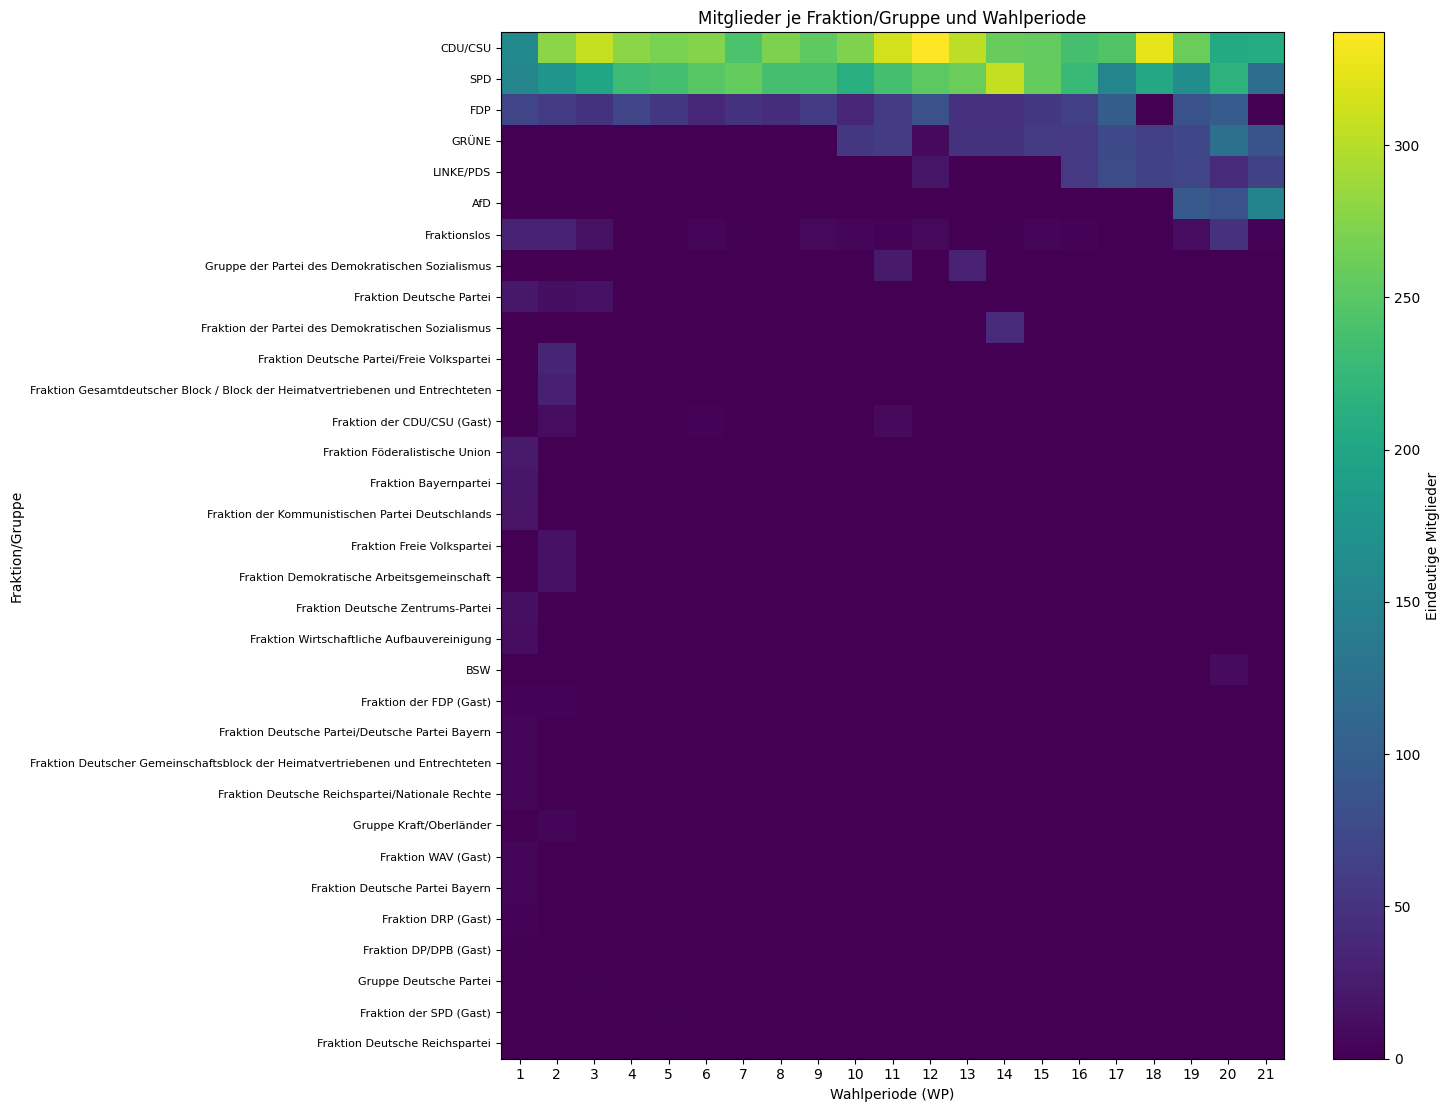

In [13]:
import matplotlib.pyplot as plt

members_by_faction_wp = (
    factions.dropna(subset=["FRAKTION_KURZ"])
    .groupby(["WP", "FRAKTION_KURZ"])["ID"]
    .nunique()
    .unstack(fill_value=0)
    .sort_index()
)
members_by_faction_wp = members_by_faction_wp[
    members_by_faction_wp.sum().sort_values(ascending=False).index
]

fig, ax = plt.subplots(figsize=(15, max(8, len(members_by_faction_wp.columns) * 0.34)))
image = ax.imshow(members_by_faction_wp.T, aspect="auto", cmap="viridis")
ax.set_xticks(range(len(members_by_faction_wp.index)))
ax.set_xticklabels(members_by_faction_wp.index.astype(int))
ax.set_yticks(range(len(members_by_faction_wp.columns)))
ax.set_yticklabels(members_by_faction_wp.columns, fontsize=8)
ax.set_xlabel("Wahlperiode (WP)")
ax.set_ylabel("Fraktion/Gruppe")
ax.set_title("Mitglieder je Fraktion/Gruppe und Wahlperiode")
fig.colorbar(image, ax=ax, label="Eindeutige Mitglieder")
fig.tight_layout()
plt.show()

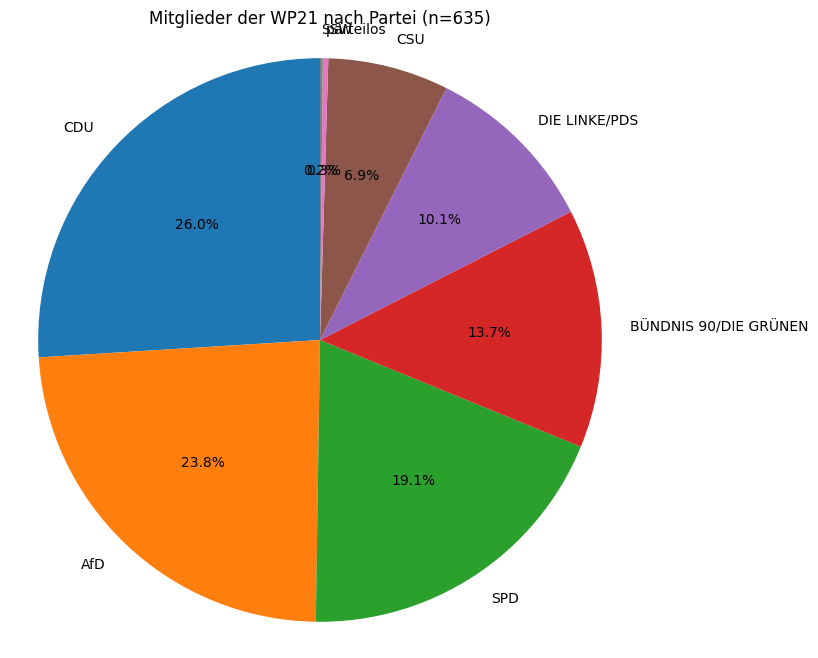

In [14]:
import matplotlib.pyplot as plt

wp21_members = (
    terms.loc[terms["WP"].eq(21), ["ID"]]
    .drop_duplicates()
    .merge(
        all_mps[["ID", "PARTEI_GRUPPE"]],
        on="ID",
        how="left",
        validate="one_to_one",
    )
)

party_counts = (
    wp21_members["PARTEI_GRUPPE"]
    .fillna("Unbekannt")
    .value_counts()
)

fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(
    party_counts,
    labels=party_counts.index,
    autopct="%1.1f%%",
    startangle=90,
)
ax.set_title(f"Mitglieder der WP21 nach Partei (n={party_counts.sum()})")
ax.axis("equal")
plt.show()